# Học phân cụm với dữ liệu khách hàng trung tâm thương mại

Notebook này dạy từng bước: K-Means, cách chọn số cụm (elbow, silhouette), hierarchical clustering và cách mô tả từng nhóm khách hàng. Đây là bài toán không có nhãn (unsupervised): không có cột đáp án, mô hình tự tìm nhóm.

Dữ liệu: 200 khách hàng, mỗi người có giới tính, tuổi, thu nhập năm (nghìn USD) và điểm chi tiêu từ 1 đến 100 do trung tâm thương mại chấm. Nguồn: bộ Mall Customers trên Kaggle.

Chuẩn bị:
1. Đặt file data3.csv cùng thư mục với notebook.
2. Cài thư viện nếu chưa có: pip install pandas numpy matplotlib seaborn scikit-learn scipy

Cách làm: đọc phần giải thích, viết code vào ô trống, chạy bằng Shift + Enter, rồi so sánh với kết quả mong đợi. Nếu kết quả khác, đọc lại đề bài và thử lại trước khi xem đáp án.

## Bước 0: Import thư viện

Mục tiêu: nạp các thư viện dùng trong toàn bộ notebook. Ô này đã viết sẵn, bạn chỉ cần chạy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

## Bước 1: Đọc dữ liệu

Mục tiêu: đưa file CSV vào DataFrame và kiểm tra kích thước.

Kiến thức: pd.read_csv đọc file thành bảng. df.shape trả về (số dòng, số cột).

Kết quả mong đợi: (200, 5).

In [2]:
df = pd.read_csv('data3.csv')
print(df.shape)
print(df.head())

(200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


## Bước 2: Đổi tên cột và kiểm tra dữ liệu

Mục tiêu: đặt tên cột ngắn để code dễ đọc, rồi kiểm tra kiểu dữ liệu và ô trống.

Kiến thức: df.rename(columns={tên_cũ: tên_mới}) đổi tên cột. Tên cột có dấu cách và ký tự đặc biệt như "Annual Income (k$)" rất dễ gõ sai.

Kết quả mong đợi: các cột mới là id, gender, age, income, score. 0 ô trống.

In [3]:
df = df.rename(columns={'CustomerID': 'id', 'Gender': 'gender', 'Age': 'age',
                        'Annual Income (k$)': 'income', 'Spending Score (1-100)': 'score'})
df.info()
print('Số ô trống:', df.isna().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      200 non-null    int64
 1   gender  200 non-null    str  
 2   age     200 non-null    int64
 3   income  200 non-null    int64
 4   score   200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
Số ô trống: 0


## Bước 3: Phân phối từng biến

Mục tiêu: xem tuổi, thu nhập và điểm chi tiêu phân bố thế nào.

Kiến thức: describe() cho trung bình, độ lệch chuẩn, min, max và các phân vị. Histogram giúp thấy hình dạng phân phối.

Kết quả mong đợi: tuổi trung bình 38,8 (từ 18 đến 70), thu nhập trung bình 60,6 k$ (từ 15 đến 137), điểm chi tiêu trung bình 50,2. Có 112 nữ và 88 nam.

         age  income  score
count  200.0   200.0  200.0
mean    38.8    60.6   50.2
std     14.0    26.3   25.8
min     18.0    15.0    1.0
25%     28.8    41.5   34.8
50%     36.0    61.5   50.0
75%     49.0    78.0   73.0
max     70.0   137.0   99.0
gender
Female    112
Male       88
Name: count, dtype: int64


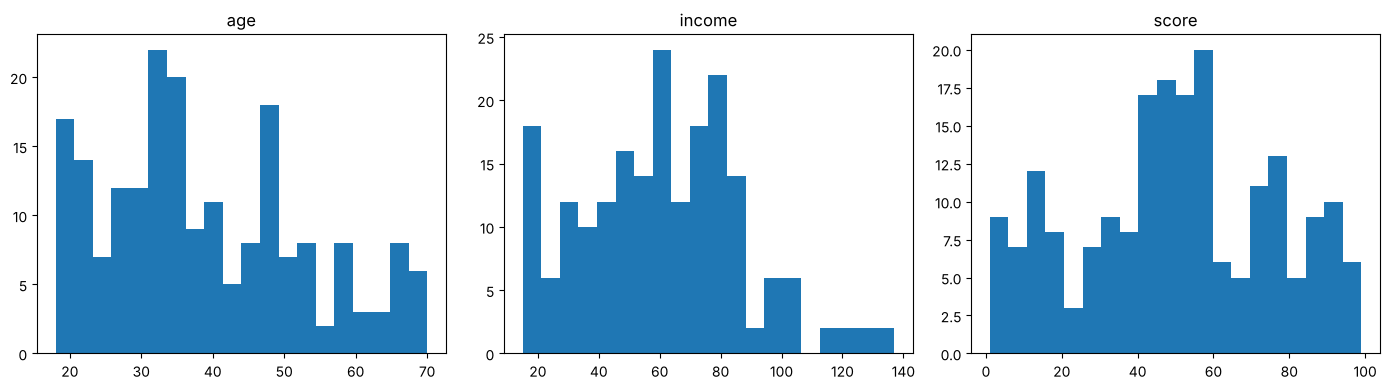

In [4]:
print(df[['age', 'income', 'score']].describe().round(1))
print(df['gender'].value_counts())

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['age', 'income', 'score']):
    ax.hist(df[col], bins=20)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Bước 4: Scatter thu nhập và điểm chi tiêu

Mục tiêu: nhìn bằng mắt xem có nhóm khách hàng nào không trước khi chạy thuật toán.

Kiến thức: trong phân cụm, vẽ dữ liệu trước giúp bạn biết kết quả của thuật toán có hợp lý không. Với 2 biến, mắt người phát hiện nhóm khá tốt.

Kết quả mong đợi: có khoảng 5 đám điểm: một đám ở giữa, và 4 đám ở 4 góc (thu nhập thấp hoặc cao kết hợp với chi tiêu thấp hoặc cao).

Câu hỏi: bạn đếm được bao nhiêu nhóm? Ghi lại con số này để so sánh với kết quả ở bước 7 và 8.

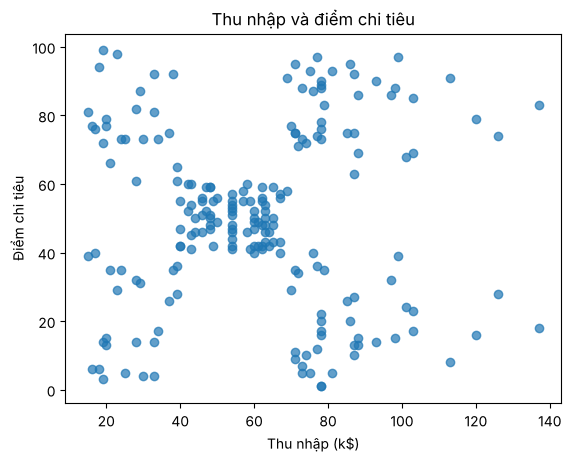

In [5]:
plt.scatter(df['income'], df['score'], alpha=0.7)
plt.xlabel('Thu nhập (k$)')
plt.ylabel('Điểm chi tiêu')
plt.title('Thu nhập và điểm chi tiêu')
plt.show()

## Bước 5: Chọn feature và chuẩn hóa

Mục tiêu: chuẩn bị ma trận X cho K-Means.

Kiến thức: K-Means đo khoảng cách Euclid. Nếu một cột có khoảng giá trị lớn hơn nhiều so với cột khác, nó sẽ quyết định khoảng cách. StandardScaler đưa mỗi cột về trung bình 0, độ lệch chuẩn 1. Ở bài này income (15 đến 137) và score (1 đến 99) có khoảng gần nhau, nhưng chuẩn hóa vẫn là thói quen tốt.

Kết quả mong đợi: X_s có kích thước (200, 2), trung bình mỗi cột bằng 0, độ lệch chuẩn bằng 1.

In [6]:
X = df[['income', 'score']]
scaler = StandardScaler()
X_s = scaler.fit_transform(X)
print(X_s.shape)
print('mean:', X_s.mean(axis=0).round(2), 'std:', X_s.std(axis=0).round(2))

(200, 2)
mean: [-0. -0.] std: [1. 1.]


## Bước 6: K-Means với k = 5

Mục tiêu: chạy K-Means lần đầu và xem kích thước từng cụm.

Kiến thức: K-Means lặp hai bước: gán mỗi điểm vào tâm gần nhất, rồi dời tâm về trung bình của các điểm trong cụm. inertia_ là tổng bình phương khoảng cách từ mỗi điểm đến tâm cụm của nó, càng nhỏ thì cụm càng chặt. n_init=10 chạy 10 lần với tâm khởi đầu khác nhau rồi giữ lần tốt nhất.

Kết quả mong đợi: inertia khoảng 65,57. Kích thước 5 cụm là 81, 39, 22, 35 và 23. Số thứ tự cụm có thể khác trên máy bạn, nhưng kích thước các cụm vẫn như vậy.

In [7]:
km = KMeans(n_clusters=5, n_init=10, random_state=42)
km.fit(X_s)
df['cluster'] = km.labels_
print('Inertia:', round(km.inertia_, 2))
print(df['cluster'].value_counts().sort_index())

Inertia: 65.57
cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


## Bước 7: Elbow method

Mục tiêu: chọn số cụm bằng cách xem inertia giảm thế nào khi tăng k.

Kiến thức: inertia luôn giảm khi tăng k (k = 200 cho inertia bằng 0). Ta tìm điểm "khuỷu tay", nơi đường cong bắt đầu đi ngang: thêm cụm sau điểm đó không làm cụm chặt hơn nhiều.

Kết quả mong đợi: inertia giảm từ 400,0 (k = 1) xuống 65,6 (k = 5). Sau k = 5, mỗi cụm thêm chỉ giảm khoảng 5 đến 10 đơn vị, nên khuỷu tay nằm ở k = 5.

1 400.0
2 269.7
3 157.7
4 108.9
5 65.6
6 55.1
7 44.9
8 37.2
9 32.4
10 30.0


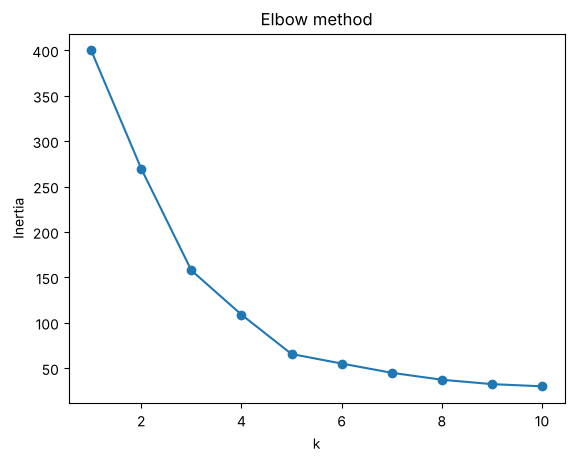

In [8]:
inertias = {}
for k in range(1, 11):
    inertias[k] = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_s).inertia_
for k, v in inertias.items():
    print(k, round(v, 1))

plt.plot(list(inertias.keys()), list(inertias.values()), marker='o')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow method')
plt.show()

## Bước 8: Silhouette score

Mục tiêu: chọn k bằng một chỉ số có giá trị lớn nhất rõ ràng.

Kiến thức: silhouette của một điểm so sánh khoảng cách trung bình đến các điểm cùng cụm (a) với khoảng cách trung bình đến cụm gần nhất khác (b): s = (b - a) / max(a, b). Giá trị từ -1 đến 1. Gần 1 là điểm nằm đúng cụm và xa cụm khác. silhouette_score lấy trung bình trên mọi điểm. Chỉ số này cần k ít nhất là 2.

Kết quả mong đợi: silhouette cao nhất ở k = 5, khoảng 0,555. k = 6 đứng thứ hai với khoảng 0,540.

Câu hỏi: elbow và silhouette có cùng gợi ý một số k không? Nếu khác nhau, bạn chọn thế nào?

2 0.321
3 0.467
4 0.494
5 0.555
6 0.54
7 0.528
8 0.455
9 0.457
10 0.443
k tốt nhất theo silhouette: 5


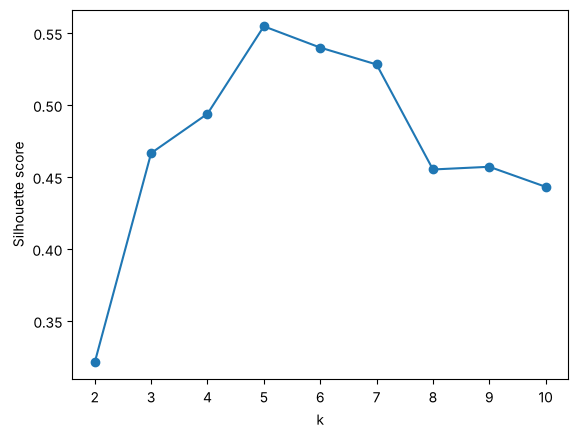

In [9]:
sil = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_s)
    sil[k] = silhouette_score(X_s, labels)
for k, v in sil.items():
    print(k, round(v, 3))
print('k tốt nhất theo silhouette:', max(sil, key=sil.get))

plt.plot(list(sil.keys()), list(sil.values()), marker='o')
plt.xlabel('k')
plt.ylabel('Silhouette score')
plt.show()

## Bước 9: Vẽ cụm và tâm cụm

Mục tiêu: nhìn kết quả K-Means với k = 5 trên đơn vị gốc.

Kiến thức: km.cluster_centers_ nằm trong không gian đã chuẩn hóa. scaler.inverse_transform đổi tâm về đơn vị gốc (k$ và điểm) để dễ đọc.

Kết quả mong đợi: 5 tâm cụm (đơn vị gốc): (55,3; 49,5) ở giữa, (86,5; 82,1) thu nhập cao chi tiêu cao, (25,7; 79,4) thu nhập thấp chi tiêu cao, (88,2; 17,1) thu nhập cao chi tiêu thấp, (26,3; 20,9) thu nhập thấp chi tiêu thấp.

   income  score
0    55.3   49.5
1    86.5   82.1
2    25.7   79.4
3    88.2   17.1
4    26.3   20.9


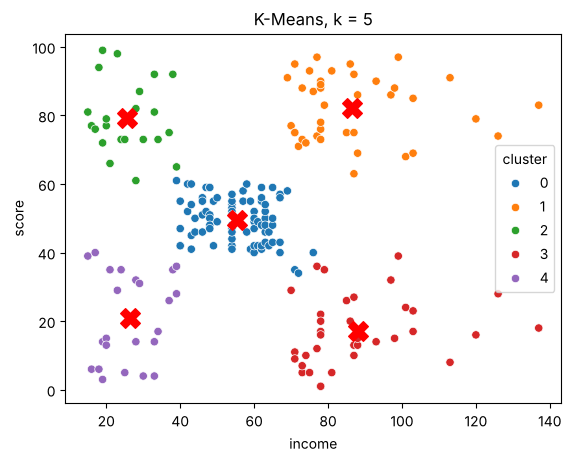

In [10]:
centers = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=['income', 'score'])
print(centers.round(1))

sns.scatterplot(data=df, x='income', y='score', hue='cluster', palette='tab10')
plt.scatter(centers['income'], centers['score'], marker='X', s=200, c='red')
plt.title('K-Means, k = 5')
plt.show()

## Bước 10: Mô tả từng cụm

Mục tiêu: biến các con số thành mô tả nhóm khách hàng mà người làm marketing hiểu được.

Kiến thức: groupby("cluster") rồi tính trung bình tuổi, thu nhập, điểm chi tiêu, tỷ lệ nữ và số khách. Đặt tên cụm theo đặc điểm nổi bật, ví dụ "thu nhập cao, chi tiêu thấp".

Kết quả mong đợi: cụm thu nhập cao và chi tiêu cao có 39 khách, tuổi trung bình 32,7. Cụm thu nhập thấp nhưng chi tiêu cao có 22 khách và trẻ nhất (25,3 tuổi). Cụm thu nhập cao chi tiêu thấp có 35 khách, tuổi trung bình 41,1. Tỷ lệ nữ ở các cụm chỉ từ 0,5 đến 0,6, nên giới tính không tách các cụm.

Câu hỏi: nếu bạn là trung tâm thương mại, bạn nhắm cụm nào cho chương trình khách hàng thân thiết? Cụm nào nên được khuyến khích chi tiêu nhiều hơn?

In [11]:
df['is_female'] = (df['gender'] == 'Female').astype(int)
profile = df.groupby('cluster').agg(
    age=('age', 'mean'), income=('income', 'mean'), score=('score', 'mean'),
    female_rate=('is_female', 'mean'), n=('id', 'size'))
print(profile.round(1))

          age  income  score  female_rate   n
cluster                                      
0        42.7    55.3   49.5          0.6  81
1        32.7    86.5   82.1          0.5  39
2        25.3    25.7   79.4          0.6  22
3        41.1    88.2   17.1          0.5  35
4        45.2    26.3   20.9          0.6  23


## Bước 11: Dendrogram

Mục tiêu: xem cách hierarchical clustering gộp dần các điểm thành cụm.

Kiến thức: hierarchical clustering kiểu gộp (agglomerative) bắt đầu với mỗi điểm là một cụm, rồi lần lượt gộp hai cụm gần nhau nhất. Phương pháp ward chọn cặp cụm mà khi gộp làm tăng tổng phương sai ít nhất. Dendrogram vẽ lịch sử gộp: chiều cao của đường nối là khoảng cách lúc gộp. Cắt ngang ở chỗ có khoảng trống dọc dài nhất cho số cụm hợp lý.

Kết quả mong đợi: nếu cắt ngang ở chiều cao khoảng 5, đường cắt đi qua 5 nhánh.

Câu hỏi: từ dendrogram, bạn chọn mấy cụm? Có khớp với k = 5 không?

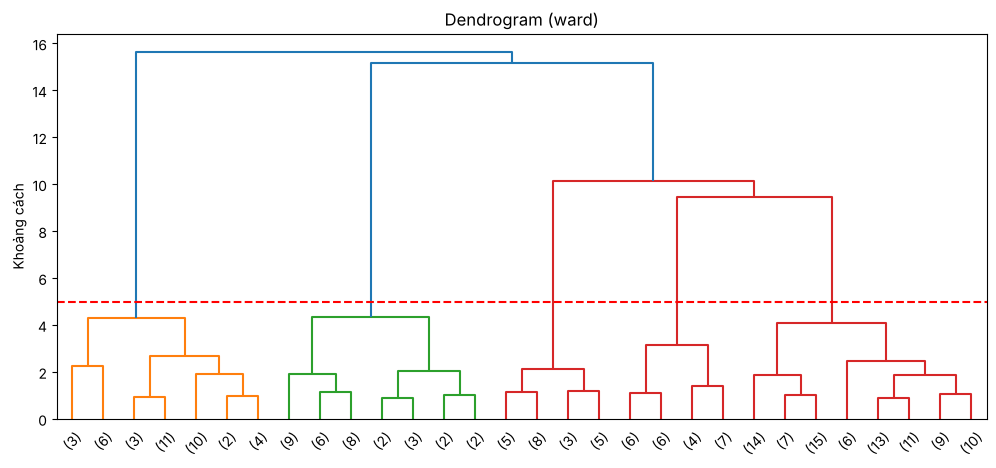

In [12]:
Z = linkage(X_s, method='ward')
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=30)
plt.axhline(y=5, color='red', linestyle='--')
plt.title('Dendrogram (ward)')
plt.ylabel('Khoảng cách')
plt.show()

## Bước 12: So sánh hierarchical với K-Means

Mục tiêu: kiểm tra hai thuật toán có chia khách hàng giống nhau không.

Kiến thức: AgglomerativeClustering(n_clusters=5, linkage="ward") cho nhãn cụm. Số thứ tự cụm của hai thuật toán không khớp nhau (cụm 0 của bên này có thể là cụm 3 của bên kia), nên không so sánh trực tiếp. adjusted_rand_score đo mức giống nhau của hai cách chia: 1 là giống hệt, gần 0 là như chia ngẫu nhiên. crosstab cho thấy cụm nào ứng với cụm nào.

Kết quả mong đợi: ARI khoảng 0,942. Crosstab cho thấy chỉ 4 khách bị xếp khác nhau giữa hai thuật toán.

In [13]:
hc = AgglomerativeClustering(n_clusters=5, linkage='ward')
df['hc'] = hc.fit_predict(X_s)
print('ARI:', round(adjusted_rand_score(df['cluster'], df['hc']), 3))
print(pd.crosstab(df['cluster'], df['hc']))

ARI: 0.942
hc        0   1   2   3   4
cluster                    
0         0   0  81   0   0
1         0  39   0   0   0
2         0   0   1  21   0
3        32   0   3   0   0
4         0   0   0   0  23


## Bước 13: So sánh các kiểu linkage

Mục tiêu: thấy cách đo khoảng cách giữa hai cụm ảnh hưởng đến kết quả.

Kiến thức: ward: gộp ít làm tăng phương sai nhất. complete: khoảng cách giữa hai điểm xa nhất. average: khoảng cách trung bình giữa mọi cặp điểm. single: khoảng cách giữa hai điểm gần nhất, dễ tạo cụm dài dạng chuỗi.

Kết quả mong đợi: ward khoảng 0,554 và complete khoảng 0,553. Average khoảng 0,479 với một cụm 102 khách. Single chỉ khoảng 0,276 với một cụm 195 khách và 4 cụm có 1 hoặc 2 khách.

Câu hỏi: vì sao single linkage cho một cụm rất lớn và vài cụm rất nhỏ?

In [14]:
for method in ['ward', 'complete', 'average', 'single']:
    labels = AgglomerativeClustering(n_clusters=5, linkage=method).fit_predict(X_s)
    print(f'{method:9s} silhouette = {silhouette_score(X_s, labels):.3f} | kích thước cụm = {np.bincount(labels)}')

ward      silhouette = 0.554 | kích thước cụm = [32 39 85 21 23]
complete  silhouette = 0.553 | kích thước cụm = [39 23 38 21 79]
average   silhouette = 0.479 | kích thước cụm = [ 38 102  36  21   3]
single    silhouette = 0.276 | kích thước cụm = [195   2   1   1   1]


## Bước 14: Thêm tuổi vào phân cụm

Mục tiêu: phân cụm với 3 biến age, income, score và xem k tốt nhất có đổi không.

Kiến thức: khi có hơn 2 biến, không thể nhìn toàn bộ dữ liệu trên một scatter, nên các chỉ số như silhouette càng cần thiết. Thêm biến làm khoảng cách thay đổi, nên số cụm tốt nhất cũng có thể đổi.

Kết quả mong đợi: silhouette thấp hơn so với 2 biến (cao nhất khoảng 0,428 ở k = 6). Với k = 6, cụm khách ở giữa bị tách thành nhóm lớn tuổi (56,3 tuổi, 45 khách) và nhóm trẻ (26,8 tuổi, 39 khách).

Câu hỏi: thêm tuổi giúp mô tả khách hàng tốt hơn hay làm cụm khó giải thích hơn?

In [15]:
X3_s = StandardScaler().fit_transform(df[['age', 'income', 'score']])
sil3 = {}
for k in range(2, 11):
    sil3[k] = silhouette_score(X3_s, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X3_s))
for k, v in sil3.items():
    print(k, round(v, 3))
best_k3 = max(sil3, key=sil3.get)
print('best_k3 =', best_k3)

df['cluster3'] = KMeans(n_clusters=best_k3, n_init=10, random_state=42).fit_predict(X3_s)
print(df.groupby('cluster3').agg(age=('age', 'mean'), income=('income', 'mean'),
                                 score=('score', 'mean'), n=('id', 'size')).round(1))

2 0.335
3 0.358
4 0.404
5 0.417
6 0.428
7 0.417
8 0.408
9 0.418
10 0.407
best_k3 = 6
           age  income  score   n
cluster3                         
0         56.3    54.3   49.1  45
1         26.8    57.1   48.1  39
2         41.9    88.9   17.0  33
3         32.7    86.5   82.1  39
4         25.0    25.3   77.6  23
5         45.5    26.3   19.4  21


## Bước 15: Không chuẩn hóa thì sao

Mục tiêu: thấy tác động của thang đo lên K-Means.

Kiến thức: nếu nhân một cột với 1000 (ví dụ đổi income từ nghìn USD sang USD), khoảng cách gần như chỉ còn phụ thuộc vào cột đó.

Kết quả mong đợi: ARI chỉ khoảng 0,285. Trong vài cụm mới, độ lệch chuẩn của score lên đến hơn 30, tức là các cụm trộn lẫn khách chi tiêu nhiều và ít, vì K-Means gần như chỉ nhìn income.

In [16]:
X_raw = df[['age', 'income', 'score']].copy()
X_raw['income'] = X_raw['income'] * 1000
labels_raw = KMeans(n_clusters=best_k3, n_init=10, random_state=42).fit_predict(X_raw)
print('ARI so với bản đã chuẩn hóa:', round(adjusted_rand_score(df['cluster3'], labels_raw), 3))
print(df.groupby(labels_raw)['score'].agg(['mean', 'std']).round(1))

ARI so với bản đã chuẩn hóa: 0.285
   mean   std
0  50.9  32.4
1  50.7  17.8
2  49.0   5.8
3  49.6  35.1
4  49.7  32.4
5  50.9  32.9


## Bước 16: Tự thử nghiệm

Không có code mẫu ở bước này. Hãy tự chọn ít nhất hai việc sau:

1. Chạy K-Means với k = 5 nhưng đổi random_state thành 0, 1, 2 và n_init=1. Kết quả có ổn định không? So sánh với n_init=10.
2. Thử DBSCAN (from sklearn.cluster import DBSCAN) với eps=0.3 và min_samples=5 trên X_s. Có bao nhiêu điểm bị đánh dấu là nhiễu (nhãn -1)?
3. Vẽ scatter age và score, tô màu theo cluster3. Nhóm nào là khách trẻ chi tiêu nhiều?
4. Viết ba câu tiếng Anh mô tả 5 nhóm khách hàng ở bước 10 cho một người quản lý marketing. Ví dụ: "Cluster 1 (n = 39) has high income and high spending, so it is the main target for loyalty offers."
